# Painel de Análise de Vendas com Visualização de Dados
Notebook `painel_vendas.ipynb` — pandas, numpy, matplotlib e seaborn.

## Etapa 1 — Preparação e Importação de Dados

**1)** Importação das bibliotecas.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns


sns.set_style('whitegrid')
sns.set_palette(sns.color_palette('deep'))

os.makedirs('graficos', exist_ok=True)


def brl(v):
    """Formata número como moeda brasileira."""
    return f"R$ {v:,.2f}".replace(',', 'X').replace('.', ',').replace('X', '.')

**2)** Carregamento do `vendas.csv`. Se o arquivo não existir, é criado um dataset fictício com `data, loja, produto, quantidade, preco_unitario` (mais `regiao` e `categoria`, necessárias para os gráficos de pizza e boxplot). Depois, `data` é convertida para `datetime`.

In [2]:
if not os.path.exists('vendas.csv'):
    rng = np.random.default_rng(42)
    n = 600

    catalogo = {  # produto: (categoria, preço base)
        'Notebook': ('Eletrônicos', 3500), 'Smartphone': ('Eletrônicos', 2000),
        'Monitor 24"': ('Eletrônicos', 900), 'Tablet': ('Eletrônicos', 1500),
        'Fone Bluetooth': ('Acessórios', 250), 'Mouse sem fio': ('Acessórios', 90),
        'Teclado Mecânico': ('Acessórios', 350), 'Webcam HD': ('Acessórios', 180),
        'Cadeira Gamer': ('Móveis', 1200), 'Mesa de Escritório': ('Móveis', 800),
    }
    lojas = {
        'BH Centro': 'Sudeste', 'Curitiba Batel': 'Sul', 'Salvador Orla': 'Nordeste',
        'Brasília Asa Sul': 'Centro-Oeste', 'Manaus Centro': 'Norte',
    }

    produtos = rng.choice(list(catalogo), n)
    loja = rng.choice(list(lojas), n, p=[0.30, 0.22, 0.20, 0.16, 0.12])
    quantidade = rng.integers(1, 9, n).astype(float)
    quantidade[rng.choice(n, 6, replace=False)] = rng.integers(25, 40, 6)  # outliers
    preco = np.array([catalogo[p][1] for p in produtos]) * rng.normal(1, 0.06, n)

    gerado = pd.DataFrame({
        'data': (pd.to_datetime('2025-01-01')
                 + pd.to_timedelta(rng.integers(0, 365, n), unit='D')).strftime('%Y-%m-%d'),
        'loja': loja,
        'regiao': [lojas[l] for l in loja],
        'categoria': [catalogo[p][0] for p in produtos],
        'produto': produtos,
        'quantidade': quantidade,
        'preco_unitario': preco.round(2),
    })
    for col in ['quantidade', 'preco_unitario']:      # valores ausentes propositais
        gerado.loc[rng.choice(n, 15, replace=False), col] = np.nan
    gerado.to_csv('vendas.csv', index=False)

df = pd.read_csv('vendas.csv')
df['data'] = pd.to_datetime(df['data'])
df.head()

,data,loja,regiao,categoria,produto,quantidade,preco_unitario
0,2025-04-05,Brasília Asa Sul,Centro-Oeste,Eletrônicos,Notebook,1.0,3290.45
1,2025-07-17,BH Centro,Sudeste,Acessórios,Webcam HD,4.0,179.08
2,2025-07-02,Salvador Orla,Nordeste,Acessórios,Teclado Mecânico,4.0,316.40
3,2025-01-31,Curitiba Batel,Sul,Acessórios,Fone Bluetooth,3.0,238.57
4,2025-08-15,Brasília Asa Sul,Centro-Oeste,Acessórios,Fone Bluetooth,2.0,252.23


**3)** Nova coluna `faturamento = quantidade * preco_unitario`.

In [3]:
df['faturamento'] = df['quantidade'] * df['preco_unitario']
df.head()

,data,loja,regiao,categoria,produto,quantidade,preco_unitario,faturamento
0,2025-04-05,Brasília Asa Sul,Centro-Oeste,Eletrônicos,Notebook,1.0,3290.45,3290.45
1,2025-07-17,BH Centro,Sudeste,Acessórios,Webcam HD,4.0,179.08,716.32
2,2025-07-02,Salvador Orla,Nordeste,Acessórios,Teclado Mecânico,4.0,316.40,1265.60
3,2025-01-31,Curitiba Batel,Sul,Acessórios,Fone Bluetooth,3.0,238.57,715.71
4,2025-08-15,Brasília Asa Sul,Centro-Oeste,Acessórios,Fone Bluetooth,2.0,252.23,504.46


**4)** Integridade do dataset.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   data            600 non-null    datetime64[us]
 1   loja            600 non-null    str           
 2   regiao          600 non-null    str           
 3   categoria       600 non-null    str           
 4   produto         600 non-null    str           
 5   quantidade      585 non-null    float64       
 6   preco_unitario  585 non-null    float64       
 7   faturamento     573 non-null    float64       
dtypes: datetime64[us](1), float64(3), str(4)
memory usage: 37.6 KB


In [5]:
df.isnull().sum()

data               0
loja               0
regiao             0
categoria          0
produto            0
quantidade        15
preco_unitario    15
faturamento       27
dtype: int64

In [6]:
df.describe()

,data,quantidade,preco_unitario,faturamento
count,600,585.000000,585.000000,573.000000
mean,2025-06-27 22:16:48,4.741880,1067.348752,4981.794276
min,2025-01-01 00:00:00,1.000000,77.440000,77.440000
25%,2025-03-30 00:00:00,2.000000,247.540000,1039.680000
50%,2025-06-28 12:00:00,4.000000,836.200000,2701.820000
75%,2025-09-22 00:00:00,7.000000,1511.580000,7117.620000
max,2025-12-31 00:00:00,37.000000,3979.140000,51386.750000
std,NaN,3.636766,995.662219,5732.968388


**5)** Valores nulos de preço e quantidade são substituídos pela média da respectiva coluna. Como o `faturamento` foi calculado antes, ele é recalculado em seguida.

In [7]:
df['preco_unitario'] = df['preco_unitario'].fillna(df['preco_unitario'].mean())
df['quantidade'] = df['quantidade'].fillna(df['quantidade'].mean())
df['faturamento'] = df['quantidade'] * df['preco_unitario']

print('Nulos restantes:', df.isnull().sum().sum())

Nulos restantes: 0


## Etapa 2 — Análise Exploratória e Estatísticas

**6)** Faturamento total por loja, do maior para o menor.

In [8]:
fat_loja = df.groupby('loja')['faturamento'].sum().sort_values(ascending=False)
fat_loja.map(brl)

loja
Curitiba Batel      R$ 742.678,02
BH Centro           R$ 730.271,98
Salvador Orla       R$ 644.132,05
Brasília Asa Sul    R$ 514.680,79
Manaus Centro       R$ 308.804,16
Name: faturamento, dtype: str

**7)** Ticket médio por loja (faturamento ÷ número de vendas).

In [9]:
ticket_medio = (df.groupby('loja')['faturamento'].sum() / df.groupby('loja').size()).sort_values(ascending=False)
ticket_medio.map(brl)

loja
Curitiba Batel      R$ 5.669,30
Salvador Orla       R$ 5.367,77
Brasília Asa Sul    R$ 5.095,85
Manaus Centro       R$ 4.349,35
BH Centro           R$ 4.125,83
dtype: str

**8)** Cinco produtos mais vendidos em quantidade.

In [10]:
top5 = df.groupby('produto')['quantidade'].sum().sort_values(ascending=False).head(5)
top5.round(0).astype(int)

produto
Smartphone        354
Webcam HD         348
Fone Bluetooth    338
Cadeira Gamer     285
Mouse sem fio     268
Name: quantidade, dtype: int64

**9)** Meses de maior e menor faturamento, no formato “Mês/Ano”.

In [11]:
fat_mensal = df.groupby(df['data'].dt.to_period('M'))['faturamento'].sum()

mes_max, mes_min = fat_mensal.idxmax(), fat_mensal.idxmin()
print(f"Maior faturamento: {mes_max.strftime('%m/%Y')} -> {brl(fat_mensal.max())}")
print(f"Menor faturamento: {mes_min.strftime('%m/%Y')} -> {brl(fat_mensal.min())}")

Maior faturamento: 07/2025 -> R$ 368.179,02
Menor faturamento: 11/2025 -> R$ 151.258,64


**10)** Colunas de mês (`.dt.month`) para facilitar agrupamentos, e o resumo mensal usado no gráfico de linhas.

In [12]:
df['mes'] = df['data'].dt.month
df['ano_mes'] = df['data'].dt.to_period('M')

resumo_mensal = df.groupby('ano_mes')['faturamento'].sum().reset_index()
resumo_mensal['mes_ano'] = resumo_mensal['ano_mes'].dt.strftime('%m/%Y')
resumo_mensal

,ano_mes,faturamento,mes_ano
0,2025-01,223089.018632,01/2025
1,2025-02,265167.498752,02/2025
2,2025-03,256108.370000,03/2025
3,2025-04,224490.454906,04/2025
4,2025-05,232054.325416,05/2025
5,2025-06,249706.282530,06/2025
6,2025-07,368179.019419,07/2025
7,2025-08,213301.922735,08/2025
8,2025-09,303585.771331,09/2025
9,2025-10,191750.199197,10/2025


## Etapa 3 — Visualizações com matplotlib e seaborn

**11)** Gráfico de barras — faturamento por loja (salvo como `faturamento_por_loja.png`).

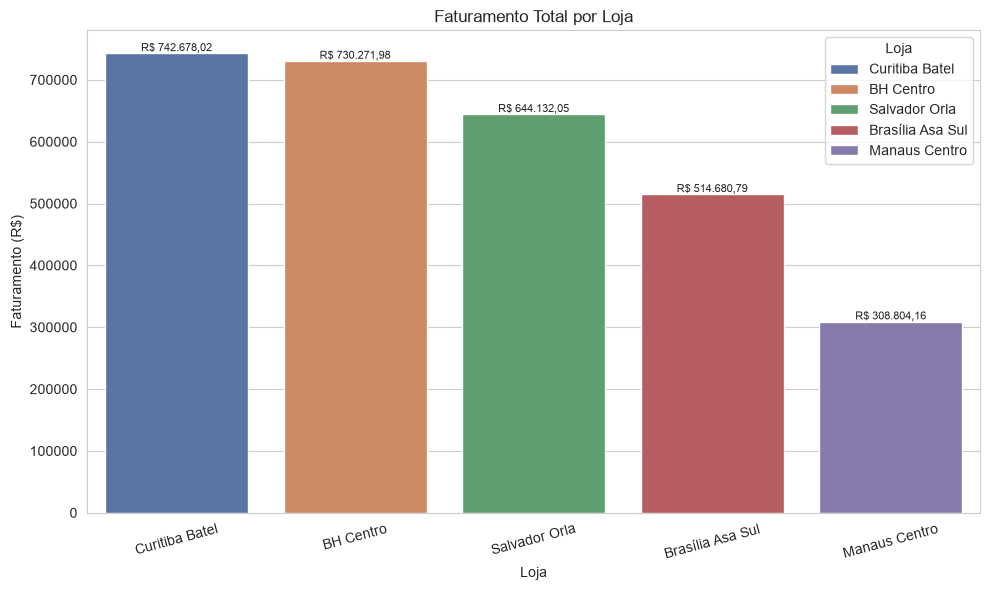

In [13]:
dados_loja = fat_loja.reset_index()

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=dados_loja, x='loja', y='faturamento', hue='loja', palette='deep', legend=True)
for i, v in enumerate(dados_loja['faturamento']):
    ax.text(i, v, brl(v), ha='center', va='bottom', fontsize=8)
ax.set_title('Faturamento Total por Loja')
ax.set_xlabel('Loja')
ax.set_ylabel('Faturamento (R$)')
ax.legend(title='Loja', loc='upper right')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('graficos/faturamento_por_loja.png', dpi=150)
plt.show()

**12)** Gráfico de linhas — evolução mensal do faturamento, com marcadores e rótulos em cada ponto.

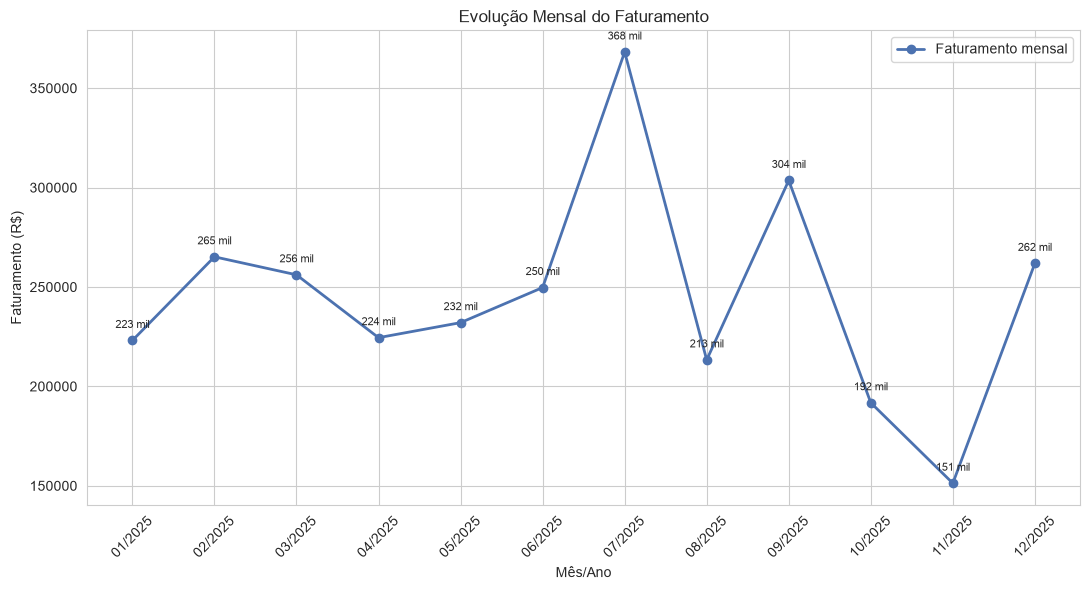

In [14]:
plt.figure(figsize=(11, 6))
plt.plot(resumo_mensal['mes_ano'], resumo_mensal['faturamento'], marker='o', linewidth=2, label='Faturamento mensal')
for x, y in zip(resumo_mensal['mes_ano'], resumo_mensal['faturamento']):
    plt.annotate(f"{y/1000:.0f} mil", (x, y), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=8)
plt.title('Evolução Mensal do Faturamento')
plt.xlabel('Mês/Ano')
plt.ylabel('Faturamento (R$)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig('graficos/evolucao_mensal_faturamento.png', dpi=150)
plt.show()

**13)** Gráfico de pizza — distribuição do faturamento por região.

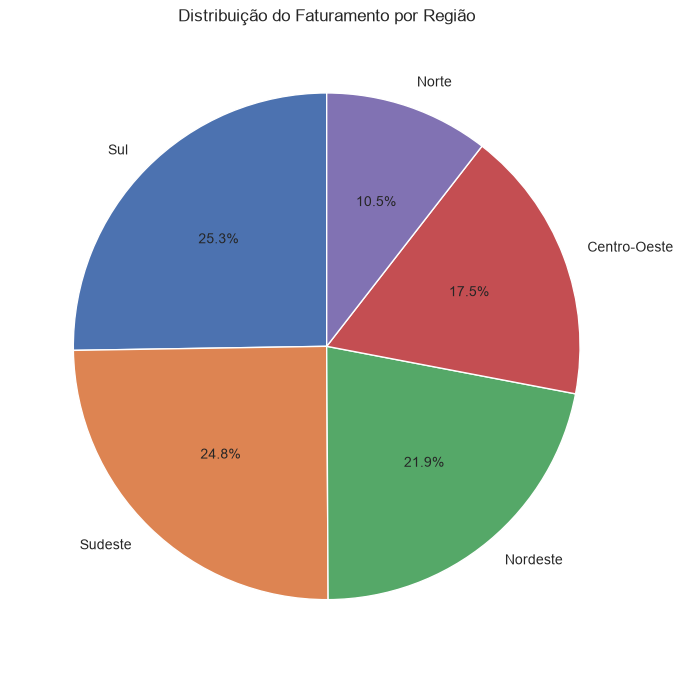

In [15]:
fat_regiao = df.groupby('regiao')['faturamento'].sum().sort_values(ascending=False)

plt.figure(figsize=(7, 7))
plt.pie(fat_regiao, labels=fat_regiao.index, autopct='%1.1f%%', startangle=90,
        colors=sns.color_palette('deep', len(fat_regiao)), wedgeprops={'edgecolor': 'white'})
plt.title('Distribuição do Faturamento por Região')
plt.tight_layout()
plt.savefig('graficos/faturamento_por_regiao.png', dpi=150)
plt.show()

**14)** Dispersão — relação entre quantidade e faturamento, destacando outliers (critério IQR sobre o faturamento).

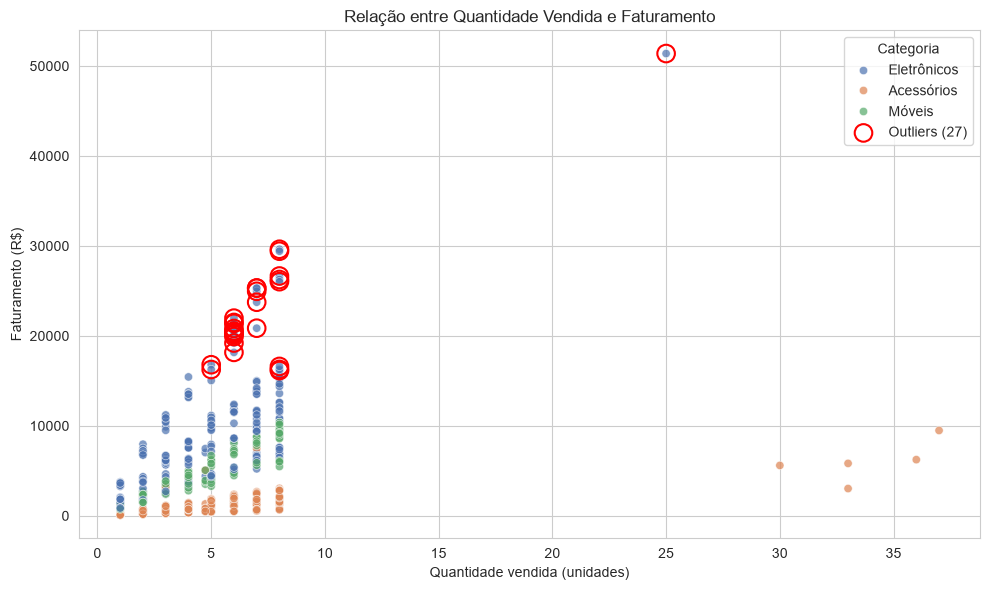

In [16]:
q1, q3 = df['faturamento'].quantile([0.25, 0.75])
limite_superior = q3 + 1.5 * (q3 - q1)
outliers = df[df['faturamento'] > limite_superior]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='quantidade', y='faturamento', hue='categoria', alpha=0.7)
plt.scatter(outliers['quantidade'], outliers['faturamento'], s=160, facecolors='none',
            edgecolors='red', linewidths=1.5, label=f'Outliers ({len(outliers)})')
plt.title('Relação entre Quantidade Vendida e Faturamento')
plt.xlabel('Quantidade vendida (unidades)')
plt.ylabel('Faturamento (R$)')
plt.legend(title='Categoria')
plt.tight_layout()
plt.savefig('graficos/dispersao_quantidade_faturamento.png', dpi=150)
plt.show()

**15)** Boxplot — distribuição dos preços unitários por categoria.

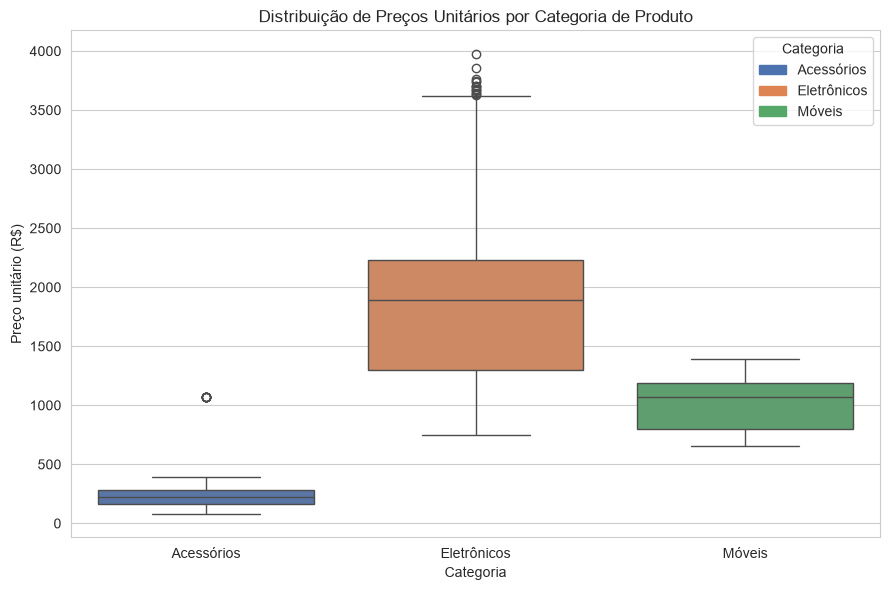

In [17]:
categorias = sorted(df['categoria'].unique())
cores = dict(zip(categorias, sns.color_palette('deep', len(categorias))))

plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x='categoria', y='preco_unitario', hue='categoria', palette=cores, order=categorias)
plt.title('Distribuição de Preços Unitários por Categoria de Produto')
plt.xlabel('Categoria')
plt.ylabel('Preço unitário (R$)')
plt.legend(handles=[mpatches.Patch(color=cores[c], label=c) for c in categorias], title='Categoria')
plt.tight_layout()
plt.savefig('graficos/boxplot_preco_por_categoria.png', dpi=150)
plt.show()

**16)** Heatmap — correlação entre variáveis numéricas.

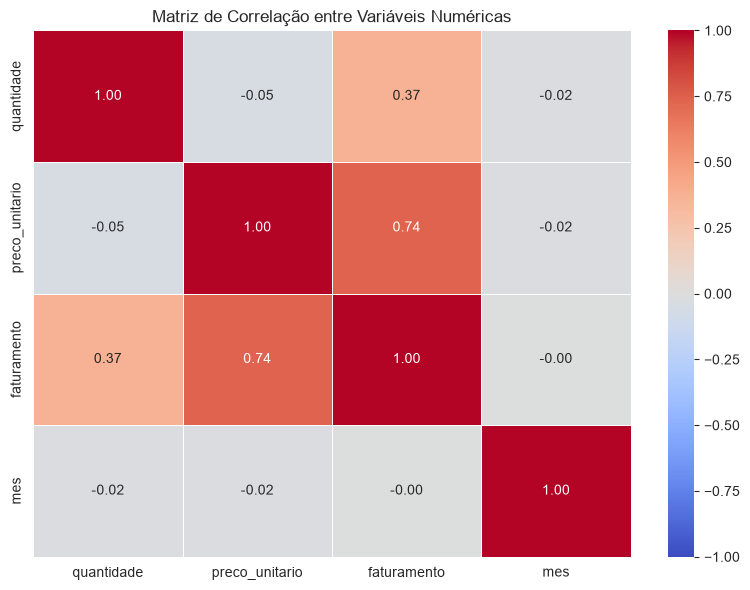

In [18]:
corr = df[['quantidade', 'preco_unitario', 'faturamento', 'mes']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação entre Variáveis Numéricas')
plt.tight_layout()
plt.savefig('graficos/heatmap_correlacao.png', dpi=150)
plt.show()

## Etapa 4 — Estilização e Apresentação

**17)** Tema global: `whitegrid` + paleta `deep`, aplicado a todos os gráficos (declarado na primeira célula e reafirmado abaixo).

In [19]:
sns.set_style('whitegrid')
sns.set_palette(sns.color_palette('deep'))
print('Tema aplicado: whitegrid + paleta deep')

Tema aplicado: whitegrid + paleta deep


**18)** Revisão de rótulos e títulos. Todos os gráficos têm título descritivo e eixos nomeados com unidade:

| Gráfico | Título | Eixos |
|---|---|---|
| Barras | Faturamento Total por Loja | Loja / Faturamento (R$) |
| Linhas | Evolução Mensal do Faturamento | Mês/Ano / Faturamento (R$) |
| Pizza | Distribuição do Faturamento por Região | — (rótulos em %) |
| Dispersão | Relação entre Quantidade Vendida e Faturamento | Quantidade (unidades) / Faturamento (R$) |
| Boxplot | Distribuição de Preços Unitários por Categoria de Produto | Categoria / Preço unitário (R$) |
| Heatmap | Matriz de Correlação entre Variáveis Numéricas | variáveis numéricas |

**19)** Layout com múltiplos gráficos (`plt.subplot`): faturamento por loja e por região lado a lado.

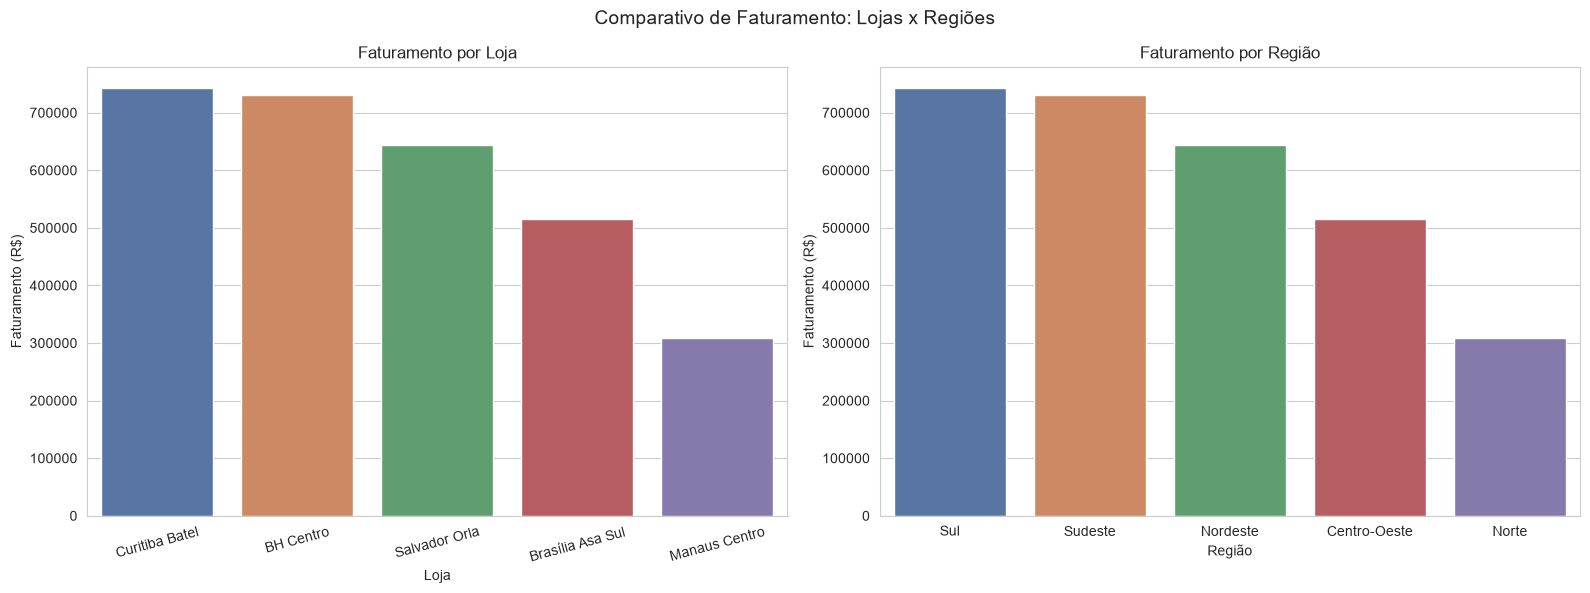

In [20]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
sns.barplot(x=fat_loja.index, y=fat_loja.values, hue=fat_loja.index, palette='deep')
plt.title('Faturamento por Loja')
plt.xlabel('Loja')
plt.ylabel('Faturamento (R$)')
plt.xticks(rotation=15)

plt.subplot(1, 2, 2)
sns.barplot(x=fat_regiao.index, y=fat_regiao.values, hue=fat_regiao.index, palette='deep')
plt.title('Faturamento por Região')
plt.xlabel('Região')
plt.ylabel('Faturamento (R$)')

plt.suptitle('Comparativo de Faturamento: Lojas x Regiões', fontsize=14)
plt.tight_layout()
plt.savefig('graficos/comparativo_loja_regiao.png', dpi=150)
plt.show()

**20)** Exportação: gráficos em `graficos/`, resumo consolidado em `resumo_analitico.csv` e comentários finais.

In [21]:
resumo = pd.concat([
    pd.DataFrame({'indicador': 'faturamento_por_loja', 'item': fat_loja.index, 'valor': fat_loja.values}),
    pd.DataFrame({'indicador': 'ticket_medio_por_loja', 'item': ticket_medio.index, 'valor': ticket_medio.values}),
    pd.DataFrame({'indicador': 'top5_produtos_quantidade', 'item': top5.index, 'valor': top5.values}),
    pd.DataFrame({'indicador': 'faturamento_por_regiao', 'item': fat_regiao.index, 'valor': fat_regiao.values}),
    pd.DataFrame({'indicador': 'faturamento_mensal', 'item': resumo_mensal['mes_ano'], 'valor': resumo_mensal['faturamento']}),
], ignore_index=True)
resumo['valor'] = resumo['valor'].round(2)
resumo.to_csv('resumo_analitico.csv', index=False, encoding='utf-8-sig')

print('Arquivos em graficos/:', sorted(os.listdir('graficos')))
resumo.head(10)

Arquivos em graficos/: ['boxplot_preco_por_categoria.png', 'comparativo_loja_regiao.png', 'dispersao_quantidade_faturamento.png', 'evolucao_mensal_faturamento.png', 'faturamento_por_loja.png', 'faturamento_por_regiao.png', 'heatmap_correlacao.png']


,indicador,item,valor
0,faturamento_por_loja,Curitiba Batel,742678.02
1,faturamento_por_loja,BH Centro,730271.98
2,faturamento_por_loja,Salvador Orla,644132.05
3,faturamento_por_loja,Brasília Asa Sul,514680.79
4,faturamento_por_loja,Manaus Centro,308804.16
5,ticket_medio_por_loja,Curitiba Batel,5669.30
6,ticket_medio_por_loja,Salvador Orla,5367.77
7,ticket_medio_por_loja,Brasília Asa Sul,5095.85
8,ticket_medio_por_loja,Manaus Centro,4349.35
9,ticket_medio_por_loja,BH Centro,4125.83


### Observações a partir das visualizações

In [22]:
corr_qf = df['quantidade'].corr(df['faturamento'])
corr_pf = df['preco_unitario'].corr(df['faturamento'])
cat_var = df.groupby('categoria')['preco_unitario'].std().idxmax()

print(f"- Barras/Pizza: a loja '{fat_loja.index[0]}' lidera com {brl(fat_loja.iloc[0])} "
      f"({fat_loja.iloc[0] / fat_loja.sum():.1%} do total); a menor é '{fat_loja.index[-1]}'.")
print(f"- Região '{fat_regiao.index[0]}' concentra {fat_regiao.iloc[0] / fat_regiao.sum():.1%} do faturamento; "
      f"'{fat_regiao.index[-1]}' tem a menor fatia ({fat_regiao.iloc[-1] / fat_regiao.sum():.1%}).")
print(f"- Ticket médio: maior em '{ticket_medio.index[0]}' ({brl(ticket_medio.iloc[0])}) "
      f"e menor em '{ticket_medio.index[-1]}' ({brl(ticket_medio.iloc[-1])}).")
print(f"- Linhas: pico em {mes_max.strftime('%m/%Y')} ({brl(fat_mensal.max())}) e menor valor em "
      f"{mes_min.strftime('%m/%Y')} ({brl(fat_mensal.min())}).")
print(f"- Produto mais vendido em quantidade: '{top5.index[0]}' ({int(top5.iloc[0])} unidades).")
print(f"- Dispersão: {len(outliers)} outliers de faturamento (acima de {brl(limite_superior)}), "
      f"em geral vendas de grande quantidade ou de itens caros.")
print(f"- Boxplot: a categoria '{cat_var}' tem a maior variação de preços unitários.")
print(f"- Heatmap: faturamento correlaciona {corr_qf:.2f} com a quantidade e {corr_pf:.2f} com o preço unitário; "
      f"o mês quase não influencia ({df['mes'].corr(df['faturamento']):.2f}).")

- Barras/Pizza: a loja 'Curitiba Batel' lidera com R$ 742.678,02 (25.3% do total); a menor é 'Manaus Centro'.
- Região 'Sul' concentra 25.3% do faturamento; 'Norte' tem a menor fatia (10.5%).
- Ticket médio: maior em 'Curitiba Batel' (R$ 5.669,30) e menor em 'BH Centro' (R$ 4.125,83).
- Linhas: pico em 07/2025 (R$ 368.179,02) e menor valor em 11/2025 (R$ 151.258,64).
- Produto mais vendido em quantidade: 'Smartphone' (354 unidades).
- Dispersão: 27 outliers de faturamento (acima de R$ 15.836,05), em geral vendas de grande quantidade ou de itens caros.
- Boxplot: a categoria 'Eletrônicos' tem a maior variação de preços unitários.
- Heatmap: faturamento correlaciona 0.37 com a quantidade e 0.74 com o preço unitário; o mês quase não influencia (-0.00).
